# Analyse des ventes - Librairie
Ce notebook applique des transformations et analyses inspirées du TD de transformation des données à un jeu de données de ventes en librairie.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Chemin robuste : fonctionne que le notebook soit lancé depuis notebooks/ ou depuis la racine du projet
RACINE = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA_PATH = RACINE / "data" / "ventes_librairie_nettoye.csv"
PLOTS_DIR = RACINE / "plots"
PLOTS_DIR.mkdir(exist_ok=True)

# Chargement du fichier CSV
df = pd.read_csv(DATA_PATH)

# Aperçu des données
df.head()

,ID_Transaction,Date,TitreLivre,Categorie,Prix,Quantite,NomClient,Email,Sexe
0,1,2023-01-15,Le Petit Prince,Jeunesse,10.99,20,Marie Dupont,marie.dupont@example.com,F
1,2,2023-01-20,1984,Classique,125.00,15,Jean Martin,jean.martin@example.com,M
2,3,2023-02-05,Harry Potter,Jeunesse,1575.00,25,Pierre Bernard,pierre.bernard@example.com,M
3,4,2023-02-12,1984,Classique,125.00,10,Sophie Dubois,sophie.dubois@example.com,F
4,5,2023-02-18,L'Étranger,Classique,9.99,30,Inconnu,client_inconnu@example.com,U


## Nettoyage de base
Nous vérifions les types de données et les valeurs manquantes.

In [2]:
# Infos générales
df.info()

# Vérification des valeurs manquantes
df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   ID_Transaction  200 non-null    int64  
 1   Date            200 non-null    str    
 2   TitreLivre      200 non-null    str    
 3   Categorie       200 non-null    str    
 4   Prix            200 non-null    float64
 5   Quantite        200 non-null    int64  
 6   NomClient       200 non-null    str    
 7   Email           200 non-null    str    
 8   Sexe            200 non-null    str    
dtypes: float64(1), int64(2), str(6)
memory usage: 14.2 KB


ID_Transaction    0
Date              0
TitreLivre        0
Categorie         0
Prix              0
Quantite          0
NomClient         0
Email             0
Sexe              0
dtype: int64

## Normalisation du prix (Min-Max et Z-score)
Nous appliquons deux méthodes :
- Min-Max : ramène entre 0 et 1
- Z-score : centrée autour de la moyenne

In [3]:
# Min-Max
df['Prix_MinMax'] = (df['Prix'] - df['Prix'].min()) / (df['Prix'].max() - df['Prix'].min())

# Z-score
df['Prix_Zscore'] = (df['Prix'] - df['Prix'].mean()) / df['Prix'].std()

# Comparaison
df[['Prix', 'Prix_MinMax', 'Prix_Zscore']].describe()

,Prix,Prix_MinMax,Prix_Zscore
count,200.000000,200.000000,2.000000e+02
mean,45.142600,0.024332,4.440892e-17
std,152.212322,0.097074,1.000000e+00
min,6.990000,0.000000,-2.506538e-01
25%,10.867500,0.002473,-2.251795e-01
50%,13.500000,0.004152,-2.078846e-01
75%,18.750000,0.007500,-1.733933e-01
max,1575.000000,1.000000,1.005081e+01


## Encodage et analyse du sexe des clients
Transformation de la variable catégorielle `Sexe` en valeur numérique.

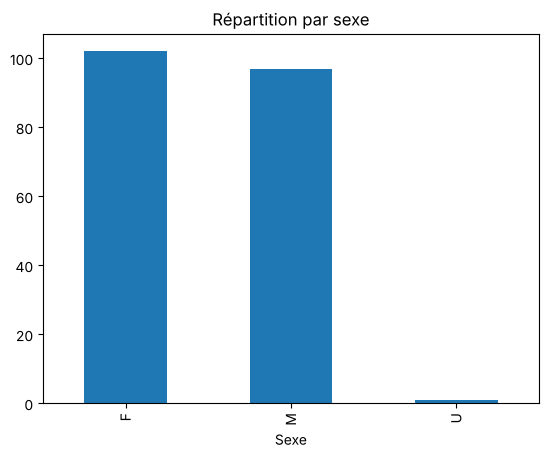

In [4]:
# Encodage
df['Sexe_encoded'] = df['Sexe'].map({'M': 0, 'F': 1, 'U': 2})

# Distribution
df['Sexe'].value_counts().plot(kind='bar', title='Répartition par sexe')
plt.savefig(PLOTS_DIR / 'repartition_sexe.png', dpi=150, bbox_inches='tight')
plt.show()

## 💰 Agrégation des ventes
Calcul du chiffre d'affaires par catégorie, et du panier moyen.


CA par catégorie:
Categorie
Classique          45639.14
Jeunesse           41103.13
Science-Fiction    38708.75
Fantasy             7478.50
Littérature         4311.60
Historique          2034.00
Philosophie         1797.26
Aventure            1502.94
Autobiographie      1326.25
Thriller            1160.25
Surréalisme          940.50
Poésie               894.88
Satire               479.40
Name: ChiffreAffaires, dtype: float64
Catégorie la plus rentable: Classique


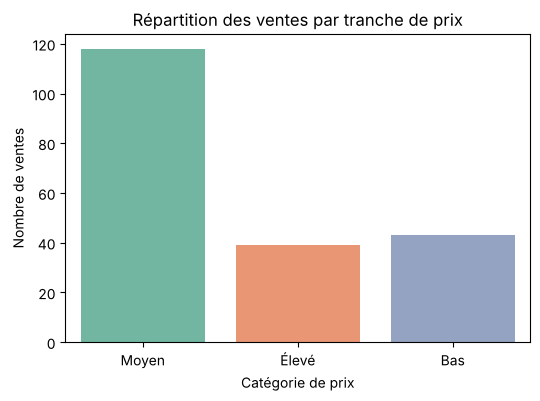

In [5]:
# Chiffre d'affaires par catégorie
df['ChiffreAffaires'] = df['Prix'] * df['Quantite']
ca_par_categorie = df.groupby('Categorie')['ChiffreAffaires'].sum().sort_values(ascending=False)
print("CA par catégorie:")
print(ca_par_categorie)

# Catégorie la plus rentable
categorie_plus_rentable = ca_par_categorie.idxmax()
print(f"Catégorie la plus rentable: {categorie_plus_rentable}")

# Panier moyen par transaction
df['PanierMoyen'] = df['ChiffreAffaires'] / df['Quantite']
df['PanierMoyen'].describe()

# Catégorisation du prix en 3 niveaux
def categoriser_prix(prix):
    if prix < 10:return 'Bas'
    elif prix <= 20: return 'Moyen'
    else:return 'Élevé'

df['Categorie_Prix'] = df['Prix'].apply(categoriser_prix)
import seaborn as sns
import matplotlib.pyplot as plt

# Répartition des ventes selon la catégorie de prix
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='Categorie_Prix', hue='Categorie_Prix', palette='Set2', legend=False)
plt.title('Répartition des ventes par tranche de prix')
plt.xlabel('Catégorie de prix')
plt.ylabel('Nombre de ventes')
plt.savefig(PLOTS_DIR / 'repartition_prix.png', dpi=150, bbox_inches='tight')
plt.show()
